# ZeRO on 32 virtual GPUs — DDP vs ZeRO-1 vs ZeRO-2 vs ZeRO-3

This notebook builds a **32-device virtual cluster** out of CPU threads, trains the same
mixed-precision MLP with plain data parallelism (DDP) and the three ZeRO stages, and
measures, per device:

* **memory**: every tensor a rank keeps is recorded in a ledger, by category,
* **communication**: every collective is charged the bytes a ring implementation sends,
* **compute**: forward/backward FLOPs, optimizer work, and wall time.

Runs on CPU only (numpy). Works locally or on Colab, with no GPU needed.

| | fp16 params (2Ψ) | fp16 grads (2Ψ) | fp32 optimizer states (12Ψ) | comm / step |
|---|---|---|---|---|
| DDP | replicated | replicated | replicated | 2Ψ (all-reduce) |
| ZeRO-1 | replicated | replicated | **sharded** | 2Ψ (reduce-scatter + all-gather) |
| ZeRO-2 | replicated | **sharded** | **sharded** | 2Ψ |
| ZeRO-3 | **sharded** | **sharded** | **sharded** | 3Ψ (2 all-gathers + reduce-scatter) |

## 1. The simulator
Everything is in this notebook. The next cells define the virtual GPUs, the collectives, the model and the training loop for each ZeRO stage.

In [1]:
import math
import threading
import time
from dataclasses import dataclass, field

import numpy as np

STAGE_NAMES = {
    0: "DDP (no ZeRO)",
    1: "ZeRO-1 (P_os)",
    2: "ZeRO-2 (P_os+g)",
    3: "ZeRO-3 (P_os+g+p)",
}

CATS = [
    "params (fp16)",
    "grads (fp16)",
    "optimizer (fp32 master+m+v)",
    "activations",
    "temp: gathered params",
    "temp: full-layer grad",
    "temp: fp32 compute copies",
]
MODEL_STATE_CATS = CATS[:3]

### Virtual GPU: a memory ledger

In [2]:
class VirtualGPU:
    """Tracks every live tensor on one simulated device, grouped by category."""

    def __init__(self, rank: int):
        self.rank = rank
        self.live: dict[str, tuple[str, int]] = {}
        self.cur = {c: 0 for c in CATS}
        self.total = 0
        self.peak = 0
        self.peak_breakdown = dict(self.cur)

    def alloc(self, name: str, cat: str, arr: np.ndarray) -> np.ndarray:
        if name in self.live:
            self.free(name)
        self.live[name] = (cat, arr.nbytes)
        self.cur[cat] += arr.nbytes
        self.total += arr.nbytes
        if self.total > self.peak:
            self.peak = self.total
            self.peak_breakdown = dict(self.cur)
        return arr

    def free(self, name: str) -> None:
        cat, nb = self.live.pop(name)
        self.cur[cat] -= nb
        self.total -= nb

    def snapshot(self) -> dict[str, int]:
        return dict(self.cur)

### Communicator: collectives between threads + ring-cost accounting

In [3]:
class Communicator:
    """
    Each collective is a rendezvous: every rank posts its array, waits at a
    barrier, computes its own output from everyone's arrays, waits again.
    The reduction always sums in rank order 0..N-1 in fp32, so results are
    deterministic and identical however the reduction is sliced.

    Bytes charged per rank (ring algorithm, message of M bytes, N ranks):
        all-reduce      2 (N-1)/N * M
        reduce-scatter    (N-1)/N * M
        all-gather        (N-1)/N * M     (M = size of the *gathered* result)
    """

    def __init__(self, world: int):
        self.world = world
        self.barrier = threading.Barrier(world, timeout=300)
        self.slots: list = [None] * world
        self.sent = np.zeros(world, dtype=np.int64)
        self.calls: list[dict[str, int]] = [dict() for _ in range(world)]
        self.wait_s = np.zeros(world)

    def _rendezvous(self, rank, x, fn):
        t0 = time.perf_counter()
        self.slots[rank] = x
        self.barrier.wait()
        out = fn(self.slots)
        self.barrier.wait()  # nobody may reuse slots until all have read
        self.wait_s[rank] += time.perf_counter() - t0
        return out

    @staticmethod
    def _sum(arrs, sl=slice(None)):
        acc = arrs[0][sl].astype(np.float32)
        for a in arrs[1:]:
            acc += a[sl]
        return acc

    def _charge(self, rank, op, nbytes):
        self.sent[rank] += nbytes
        self.calls[rank][op] = self.calls[rank].get(op, 0) + 1

    def all_reduce(self, rank: int, x: np.ndarray) -> np.ndarray:
        n = self.world
        self._charge(rank, "all_reduce", 2 * (n - 1) * x.nbytes // n)
        return self._rendezvous(rank, x, lambda s: self._sum(s).astype(x.dtype))

    def reduce_scatter(self, rank: int, x: np.ndarray) -> np.ndarray:
        n = self.world
        k = x.size // n
        self._charge(rank, "reduce_scatter", (n - 1) * x.nbytes // n)
        sl = slice(rank * k, (rank + 1) * k)
        return self._rendezvous(rank, x, lambda s: self._sum(s, sl).astype(x.dtype))

    def all_gather(self, rank: int, shard: np.ndarray) -> np.ndarray:
        n = self.world
        self._charge(rank, "all_gather", (n - 1) * shard.nbytes)
        return self._rendezvous(rank, shard, lambda s: np.concatenate(s))

### Model: an MLP whose layers are flat, padded, shardable parameter vectors

In [4]:
@dataclass
class LayerSpec:
    fan_in: int
    fan_out: int
    world: int

    @property
    def numel(self) -> int:
        return self.fan_in * self.fan_out + self.fan_out

    @property
    def padded(self) -> int:
        return math.ceil(self.numel / self.world) * self.world

    @property
    def shard(self) -> int:
        return self.padded // self.world

    def unflatten(self, flat):
        k = self.fan_in * self.fan_out
        return flat[:k].reshape(self.fan_in, self.fan_out), flat[k : self.numel]

    def flatten(self, W, b):
        out = np.zeros(self.padded, dtype=np.float32)
        k = self.fan_in * self.fan_out
        out[:k] = W.ravel()
        out[k : self.numel] = b
        return out


def init_master(layers, seed=0):
    """Same fp32 init on every rank (as if broadcast from rank 0)."""
    rng = np.random.default_rng(seed)
    out = []
    for L in layers:
        W = rng.standard_normal((L.fan_in, L.fan_out)).astype(np.float32) / np.sqrt(L.fan_in)
        b = np.zeros(L.fan_out, dtype=np.float32)
        out.append(L.flatten(W, b))
    return out


@dataclass
class Adam:
    lr: float = 1e-3
    b1: float = 0.9
    b2: float = 0.999
    eps: float = 1e-8

    def update(self, p, m, v, g, t):
        """In-place, purely element-wise -> identical on a shard or on the whole."""
        m *= self.b1
        m += (1 - self.b1) * g
        v *= self.b2
        v += (1 - self.b2) * g * g
        mhat = m / (1 - self.b1**t)
        vhat = v / (1 - self.b2**t)
        p -= self.lr * mhat / (np.sqrt(vhat) + self.eps)

### One rank's training loop

In [5]:
class Worker:
    def __init__(self, rank, stage, layers, master_init, comm, batch, teacher, opt):
        self.rank, self.stage, self.layers, self.comm = rank, stage, layers, comm
        self.world = comm.world
        self.batch, self.teacher, self.opt = batch, teacher, opt
        self.gpu = VirtualGPU(rank)
        self.flops = 0
        self.opt_elems = 0
        self.losses: list[float] = []
        self.step_times: list[float] = []
        g, S, r = self.gpu, stage, rank

        self.p16, self.p16_shard, self.grad16, self.grad_shard = {}, {}, {}, {}
        self.master, self.m, self.v = {}, {}, {}
        for i, (L, full) in enumerate(zip(layers, master_init)):
            sl = slice(r * L.shard, (r + 1) * L.shard)
            # --- fp16 working parameters ---
            if S < 3:
                self.p16[i] = g.alloc(f"p16_{i}", CATS[0], full.astype(np.float16))
            else:
                self.p16_shard[i] = g.alloc(f"p16_{i}", CATS[0], full[sl].astype(np.float16))
            # --- fp16 gradient buffer ---
            if S < 2:
                self.grad16[i] = g.alloc(f"g16_{i}", CATS[1], np.zeros(L.padded, np.float16))
            else:
                self.grad_shard[i] = g.alloc(f"g16_{i}", CATS[1], np.zeros(L.shard, np.float16))
            # --- fp32 optimizer states: master copy + Adam m + Adam v ---
            src = full if S == 0 else full[sl]
            self.master[i] = g.alloc(f"master_{i}", CATS[2], src.copy())
            self.m[i] = g.alloc(f"m_{i}", CATS[2], np.zeros_like(src))
            self.v[i] = g.alloc(f"v_{i}", CATS[2], np.zeros_like(src))

    # ---- parameters: ZeRO-3 materialises a layer only while it is used ----
    def get_params(self, i):
        if self.stage < 3:
            return self.p16[i]
        full = self.comm.all_gather(self.rank, self.p16_shard[i])
        return self.gpu.alloc("gathered", CATS[4], full)

    def release_params(self, i):
        if self.stage == 3:
            self.gpu.free("gathered")

    # ---- gradients ----
    def handle_grad(self, i, grad16):
        S, g, r, c = self.stage, self.gpu, self.rank, self.comm
        if S == 0:  # DDP: all-reduce each layer's grad (bucketed, during backward)
            self.grad16[i][:] = c.all_reduce(r, grad16)
        elif S == 1:  # ZeRO-1: keep full local grad; reduce later
            self.grad16[i][:] = grad16
        else:  # ZeRO-2/3: reduce-scatter now, keep only my shard
            self.grad_shard[i][:] = c.reduce_scatter(r, grad16)

    def data(self, step):
        rng = np.random.default_rng(1_000_003 * step + self.rank)
        x = rng.standard_normal((self.batch, self.layers[0].fan_in)).astype(np.float32)
        return x, np.tanh(x @ self.teacher)

    def train_step(self, step):
        g, n, L, c, r = self.gpu, self.world, self.layers, self.comm, self.rank
        last = len(L) - 1
        x, y = self.data(step)

        # ---------------- forward ----------------
        acts, h = [], x
        g.alloc("h0", CATS[3], h)
        for i, spec in enumerate(L):
            W, b = spec.unflatten(self.get_params(i))
            W32 = g.alloc("W32", CATS[6], W.astype(np.float32))
            z = h @ W32 + b.astype(np.float32)
            g.free("W32")
            self.release_params(i)
            self.flops += 2 * self.batch * spec.fan_in * spec.fan_out
            g.alloc(f"z{i}", CATS[3], z)
            acts.append((h, z))
            if i < last:
                h = np.maximum(z, 0)
                g.alloc(f"h{i + 1}", CATS[3], h)
            else:
                h = z
        diff = h - y
        loss = float(np.mean(diff * diff))

        # ---------------- backward ----------------
        dh = 2 * diff / diff.size
        for i in reversed(range(len(L))):
            spec = L[i]
            h_in, z = acts[i]
            dz = dh * (z > 0) if i < last else dh
            W, _ = spec.unflatten(self.get_params(i))
            W32 = g.alloc("W32", CATS[6], W.astype(np.float32))
            dW, db = h_in.T @ dz, dz.sum(0)
            dh = dz @ W32.T
            g.free("W32")
            self.release_params(i)
            self.flops += 4 * self.batch * spec.fan_in * spec.fan_out
            g.free(f"z{i}")
            g.free(f"h{i}")
            # pre-divide by N so that the SUM over ranks is the global MEAN gradient
            g32 = g.alloc("grad32", CATS[6], spec.flatten(dW, db))
            g32 /= n
            grad16 = g.alloc("fullgrad", CATS[5], g32.astype(np.float16))
            g.free("grad32")
            self.handle_grad(i, grad16)
            g.free("fullgrad")

        # ---------------- optimizer ----------------
        t = step + 1
        for i, spec in enumerate(L):
            if self.stage == 0:
                grad = self.grad16[i].astype(np.float32)
            elif self.stage == 1:
                grad = c.reduce_scatter(r, self.grad16[i]).astype(np.float32)
            else:
                grad = self.grad_shard[i].astype(np.float32)
            g.alloc("optgrad32", CATS[6], grad)
            self.opt.update(self.master[i], self.m[i], self.v[i], grad, t)
            g.free("optgrad32")
            self.opt_elems += grad.size
            new16 = self.master[i].astype(np.float16)
            if self.stage == 0:
                self.p16[i][:] = new16
            elif self.stage in (1, 2):  # everyone needs all params for next fwd
                full = g.alloc("gathered", CATS[4], c.all_gather(r, new16))
                self.p16[i][:] = full
                g.free("gathered")
            else:  # ZeRO-3: keep only my shard
                self.p16_shard[i][:] = new16
        return loss

    def run(self, steps):
        for s in range(steps):
            t0 = time.perf_counter()
            self.losses.append(self.train_step(s))
            self.step_times.append(time.perf_counter() - t0)

### Driver

In [6]:
@dataclass
class Result:
    stage: int
    world: int
    psi: int  # number of (unpadded) parameters
    losses: np.ndarray  # global mean loss per step
    model_state: list  # per-rank dict cat -> bytes, after training
    peak: list  # per-rank peak bytes
    peak_breakdown: list  # per-rank dict at the moment of the peak
    sent_per_step: np.ndarray  # per-rank bytes sent per step
    calls_per_step: dict
    flops_per_step: int
    opt_elems_per_step: int
    step_time: float
    comm_wait_frac: float
    final_params: list = field(repr=False, default_factory=list)

    @property
    def name(self):
        return STAGE_NAMES[self.stage]


def run(stage, world=32, dims=(256, 512, 512, 512, 512, 64), batch=16, steps=20,
        lr=1e-3, seed=0) -> Result:
    layers = [LayerSpec(a, b, world) for a, b in zip(dims[:-1], dims[1:])]
    master_init = init_master(layers, seed)
    teacher = np.random.default_rng(seed + 1).standard_normal((dims[0], dims[-1])).astype(
        np.float32) / np.sqrt(dims[0])
    comm = Communicator(world)
    workers = [Worker(r, stage, layers, master_init, comm, batch, teacher, Adam(lr))
               for r in range(world)]
    errors = []

    def target(w):
        try:
            w.run(steps)
        except BaseException as e:  # don't leave the others hanging at the barrier
            errors.append(e)
            comm.barrier.abort()

    threads = [threading.Thread(target=target, args=(w,)) for w in workers]
    t0 = time.perf_counter()
    for t in threads:
        t.start()
    for t in threads:
        t.join()
    wall = time.perf_counter() - t0
    if errors:
        raise errors[0]

    if stage == 0:
        final = [workers[0].master[i].copy() for i in range(len(layers))]
    else:  # stitch the shards back together
        final = [np.concatenate([w.master[i] for w in workers]) for i in range(len(layers))]

    w0 = workers[0]
    return Result(
        stage=stage, world=world, psi=sum(L.numel for L in layers),
        losses=np.mean([w.losses for w in workers], axis=0),
        model_state=[w.gpu.snapshot() for w in workers],
        peak=[w.gpu.peak for w in workers],
        peak_breakdown=[w.gpu.peak_breakdown for w in workers],
        sent_per_step=comm.sent / steps,
        calls_per_step={k: v / steps for k, v in comm.calls[0].items()},
        flops_per_step=w0.flops // steps,
        opt_elems_per_step=w0.opt_elems // steps,
        step_time=wall / steps,
        comm_wait_frac=float(np.mean(comm.wait_s) / wall),
        final_params=final,
    )

### Closed-form formulas from the ZeRO paper (Rajbhandari et al., 2020)

In [7]:
def zero_model_state_bytes(psi, n, stage, k=12):
    """(params, grads, optimizer) bytes per GPU with mixed-precision Adam (K=12).

    Uses unpadded psi: the simulator matches exactly when N divides every layer's size
    (true for the default model and N = 2..32); otherwise padding adds a few bytes.
    """
    p, g, o = 2.0 * psi, 2.0 * psi, float(k) * psi
    if stage >= 1:
        o /= n
    if stage >= 2:
        g /= n
    if stage >= 3:
        p /= n
    return p, g, o


def zero_comm_bytes(psi, n, stage):
    """Bytes sent per GPU per step with ring collectives on fp16 (2-byte) data."""
    ring = (n - 1) / n * 2 * psi  # one reduce-scatter OR one all-gather of all params
    return 3 * ring if stage == 3 else 2 * ring

In [8]:
import matplotlib.pyplot as plt

WORLD = 32
MB = 2**20
# Colors: validated categorical palette, assigned in fixed order
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
INK, INK2, SURF, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titleweight": "bold", "legend.frameon": False,
})

from IPython.display import Markdown, display
def show_table(rows, digits=3):
    fmt = lambda v: f"{v:,.{digits}f}" if isinstance(v, float) else (f"{v:,}" if isinstance(v, int) else str(v))
    cols = list(rows[0])
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    out += ["| " + " | ".join(fmt(r[c]) for c in cols) + " |" for r in rows]
    display(Markdown("\n".join(out)))

## 2. The virtual cluster: 32 ranks and 3 collectives

Each rank is a thread. Before training on the cluster, check the collectives on 32 ranks:

* **all-reduce**: everyone gets the sum of everyone's vector
* **reduce-scatter**: rank *r* gets only chunk *r* of that sum
* **all-gather**: everyone gets the concatenation of everyone's chunk

All-reduce = reduce-scatter followed by all-gather. That is why ZeRO-1/2 cost the same as DDP.

In [9]:
import threading
comm = Communicator(WORLD)
out = {}
def rank_fn(r):
    x = np.full(WORLD * 4, r, dtype=np.float32)          # rank r contributes the value r
    out[r] = (comm.all_reduce(r, x), comm.reduce_scatter(r, x), comm.all_gather(r, np.array([r], np.float32)))
ts = [threading.Thread(target=rank_fn, args=(r,)) for r in range(WORLD)]
[t.start() for t in ts]; [t.join() for t in ts]

expect = sum(range(WORLD))
assert all((out[r][0] == expect).all() for r in range(WORLD))
assert all(out[r][1].shape == (4,) and (out[r][1] == expect).all() for r in range(WORLD))
assert all((out[r][2] == np.arange(WORLD)).all() for r in range(WORLD))
print(f"{WORLD} virtual GPUs OK. all-reduce -> {out[7][0][:3]}..., "
      f"reduce-scatter -> shape {out[7][1].shape}, all-gather -> {out[7][2][:6]}...")
print("bytes sent by rank 0:", comm.sent[0], "calls:", comm.calls[0])

32 virtual GPUs OK. all-reduce -> [496. 496. 496.]..., reduce-scatter -> shape (4,), all-gather -> [0. 1. 2. 3. 4. 5.]...
bytes sent by rank 0: 1612 calls: {'all_reduce': 1, 'reduce_scatter': 1, 'all_gather': 1}


## 3. The demo model

A 5-layer MLP (256 → 512 → 512 → 512 → 512 → 64, ReLU), regressing a fixed random "teacher".
Each layer's (W, b) is flattened into one vector, padded to a multiple of 32, and split
into 32 contiguous shards. **Rank r owns shard r of every layer.**

Mixed-precision Adam, as in the ZeRO paper:
* fp16 working weights (2 B/param) used for forward/backward
* fp16 gradients (2 B/param)
* fp32 master weights + Adam momentum + Adam variance (4+4+4 = **12 B/param**, *K = 12*)

Every rank gets its own micro-batch of 16 (global batch 512).

In [10]:
STEPS = 20
results = {s: run(s, world=WORLD, steps=STEPS) for s in range(4)}
PSI = results[0].psi
print(f"Ψ = {PSI:,} parameters  |  16Ψ = {16*PSI/MB:.2f} MiB of model state if fully replicated")
for s, r in results.items():
    print(f"{r.name:20s} final loss {r.losses[-1]:.5f}   step {r.step_time*1e3:6.1f} ms")

Ψ = 952,384 parameters  |  16Ψ = 14.53 MiB of model state if fully replicated
DDP (no ZeRO)        final loss 0.34368   step   77.3 ms
ZeRO-1 (P_os)        final loss 0.34368   step   91.8 ms
ZeRO-2 (P_os+g)      final loss 0.34368   step   89.8 ms
ZeRO-3 (P_os+g+p)    final loss 0.34368   step  116.7 ms


## 4. Same math, different memory: correctness first

ZeRO changes **where** state lives. It does not change the numbers. All stages must train
identically. Reductions here always sum in the same rank order, and Adam is element-wise,
so we can check for *bitwise* equality against DDP.

ZeRO-1 (P_os)        max |param - DDP param| = 0.0e+00   losses identical: True
ZeRO-2 (P_os+g)      max |param - DDP param| = 0.0e+00   losses identical: True
ZeRO-3 (P_os+g+p)    max |param - DDP param| = 0.0e+00   losses identical: True


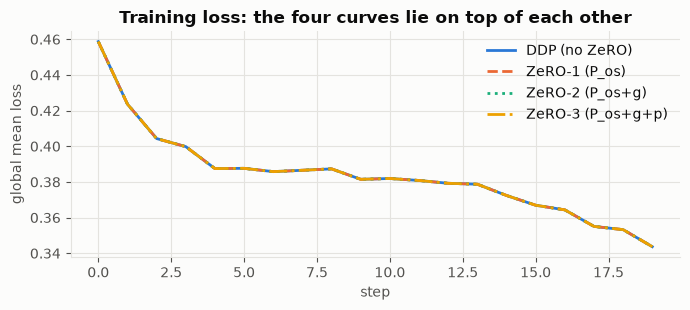

In [11]:
for s in (1, 2, 3):
    d = max(np.abs(a - b).max() for a, b in zip(results[s].final_params, results[0].final_params))
    print(f"{results[s].name:20s} max |param - DDP param| = {d:.1e}   losses identical: "
          f"{np.array_equal(results[s].losses, results[0].losses)}")

fig, ax = plt.subplots(figsize=(7, 3.2))
styles = ["-", "--", ":", "-."]
for s, r in results.items():
    ax.plot(r.losses, styles[s], color=C[s], lw=2, label=r.name)
ax.set(xlabel="step", ylabel="global mean loss", title="Training loss: the four curves lie on top of each other")
ax.legend(); plt.tight_layout(); plt.show()

## 5. Who holds what?

Each panel is one kind of model state. Rows are the 32 ranks, columns are the 32 shards
of the parameter vector. A filled cell means that rank keeps that shard in memory.
DDP fills everything. Each ZeRO stage empties one more row of panels, and what is left
is the diagonal: rank *r* keeps only shard *r*.

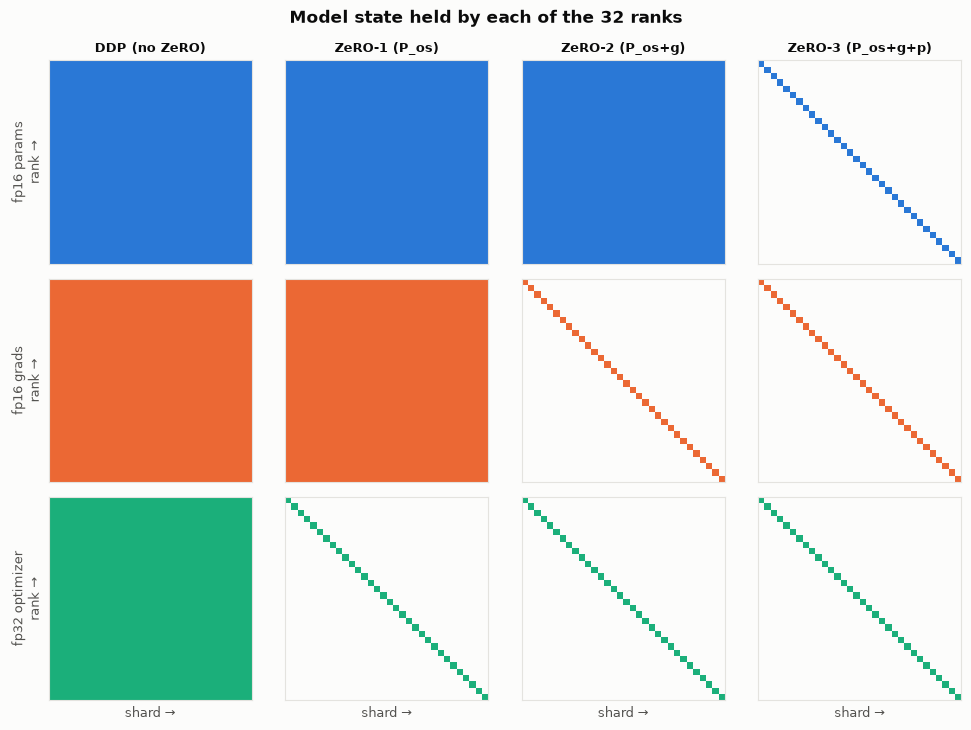

In [12]:
from matplotlib.colors import ListedColormap
kinds = ["fp16 params", "fp16 grads", "fp32 optimizer"]
fig, axes = plt.subplots(3, 4, figsize=(10, 7.4))
for s in range(4):
    for k in range(3):
        sharded = {0: s >= 3, 1: s >= 2, 2: s >= 1}[k]
        held = np.eye(WORLD) if sharded else np.ones((WORLD, WORLD))
        ax = axes[k, s]
        ax.imshow(held, cmap=ListedColormap([SURF, C[k]]), vmin=0, vmax=1, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(GRID)
        if k == 0: ax.set_title(STAGE_NAMES[s], fontsize=9)
        if s == 0: ax.set_ylabel(f"{kinds[k]}\nrank →", fontsize=9)
        if k == 2: ax.set_xlabel("shard →", fontsize=9)
fig.suptitle("Model state held by each of the 32 ranks", fontweight="bold")
plt.tight_layout(); plt.show()

## 6. Memory per virtual GPU: measured vs. the paper's formula

Persistent model state per rank, after training (activations and temporaries freed):

* DDP: (2 + 2 + K)Ψ = 16Ψ
* ZeRO-1: 2Ψ + 2Ψ + KΨ/N
* ZeRO-2: 2Ψ + (2+K)Ψ/N
* ZeRO-3: (2+2+K)Ψ/N

In [13]:
rows = []
for s, r in results.items():
    ms = r.model_state[0]
    p, g, o = zero_model_state_bytes(PSI, WORLD, s)
    meas = sum(ms[c] for c in MODEL_STATE_CATS)
    assert all(rr == r.model_state[0] for rr in r.model_state), "ranks should be symmetric"
    rows.append({"stage": r.name,
                 "params MiB": ms[CATS[0]]/MB, "grads MiB": ms[CATS[1]]/MB, "optim MiB": ms[CATS[2]]/MB,
                 "measured MiB": meas/MB, "formula MiB": (p+g+o)/MB,
                 "bytes/param": meas/PSI, "DDP ÷ this": f"{sum(results[0].model_state[0][c] for c in MODEL_STATE_CATS)/meas:.1f}×"})
show_table(rows)

| stage | params MiB | grads MiB | optim MiB | measured MiB | formula MiB | bytes/param | DDP ÷ this |
|---|---|---|---|---|---|---|---|
| DDP (no ZeRO) | 1.817 | 1.817 | 10.899 | 14.532 | 14.532 | 16.000 | 1.0× |
| ZeRO-1 (P_os) | 1.817 | 1.817 | 0.341 | 3.974 | 3.974 | 4.375 | 3.7× |
| ZeRO-2 (P_os+g) | 1.817 | 0.057 | 0.341 | 2.214 | 2.214 | 2.438 | 6.6× |
| ZeRO-3 (P_os+g+p) | 0.057 | 0.057 | 0.341 | 0.454 | 0.454 | 0.500 | 32.0× |

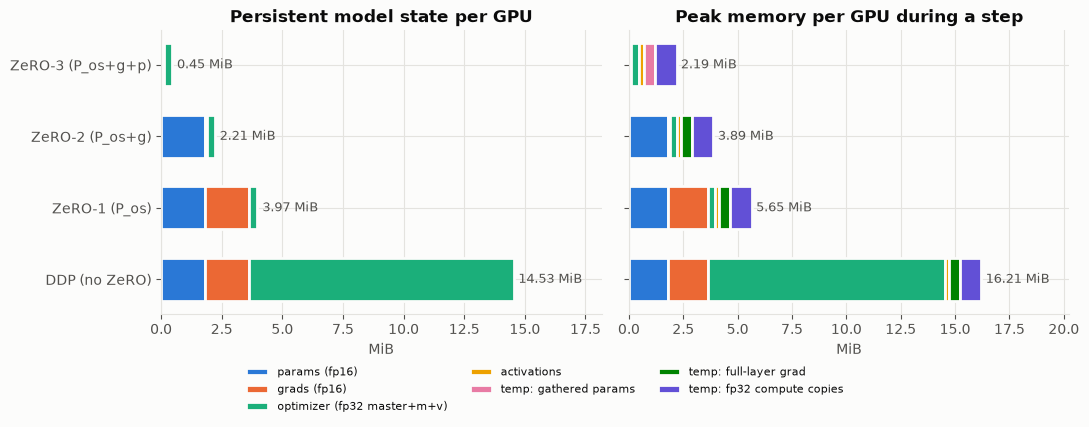

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
names = [results[s].name for s in range(4)]
for ax, which, title in [(axes[0], "state", "Persistent model state per GPU"),
                         (axes[1], "peak", "Peak memory per GPU during a step")]:
    left = np.zeros(4)
    cats = MODEL_STATE_CATS if which == "state" else CATS
    for ci, cat in enumerate(cats):
        vals = np.array([(results[s].model_state[0] if which == "state" else results[s].peak_breakdown[0])[cat]
                         for s in range(4)]) / MB
        ax.barh(names, vals, left=left, color=C[ci], label=cat, edgecolor=SURF, linewidth=2, height=0.6)
        left += vals
    for i, v in enumerate(left):
        ax.text(v + 0.2, i, f"{v:.2f} MiB", va="center", color=INK2, fontsize=9)
    ax.set_title(title); ax.set_xlabel("MiB"); ax.invert_yaxis(); ax.set_xlim(0, left.max() * 1.25)
h, l = axes[1].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

**Reading the peak chart:** ZeRO-1/2/3 do not shard activations (ZeRO-R's P_a partitions *checkpointed*
activations, which is a separate technique). The peak also counts every short-lived buffer the rank
creates, including fp32 copies of a layer's weights and gradient used for compute. ZeRO-2 and ZeRO-3 also need short-lived buffers:

* ZeRO-2/3: one layer's *full* gradient exists briefly before it is reduce-scattered
* ZeRO-3: one layer's *full* parameters exist briefly after the all-gather, then are thrown away

So ZeRO-3 peak = shards + about one layer's working buffers + activations. That is why ZeRO-3 can hold
models far larger than one device, as long as the largest layer *plus the activations* fit.

## 7. Communication per step

Measured bytes each rank sends, against the paper's ring-collective analysis:

* DDP: one all-reduce of the gradients = 2Ψ·(N-1)/N elements
* ZeRO-1/2: reduce-scatter the grads + all-gather the updated params. Same total, nothing extra.
* ZeRO-3: all-gather the params in forward, **again** in backward, and reduce-scatter the grads.
  That is 3Ψ·(N-1)/N, or **1.5×**.

| stage | collectives / step | measured MiB/step | formula MiB/step | × DDP |
|---|---|---|---|---|
| DDP (no ZeRO) | 5× all_reduce | 3.520 | 3.520 | 1.000 |
| ZeRO-1 (P_os) | 5× reduce_scatter, 5× all_gather | 3.520 | 3.520 | 1.000 |
| ZeRO-2 (P_os+g) | 5× reduce_scatter, 5× all_gather | 3.520 | 3.520 | 1.000 |
| ZeRO-3 (P_os+g+p) | 10× all_gather, 5× reduce_scatter | 5.279 | 5.279 | 1.500 |

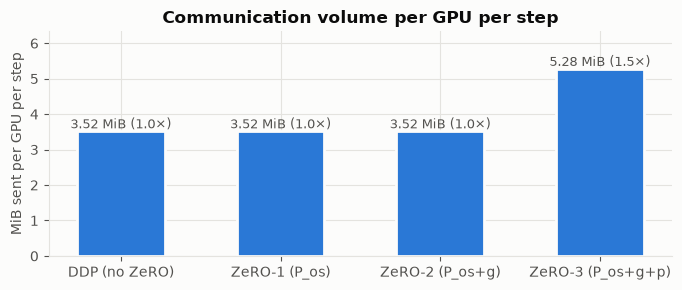

In [15]:
rows = []
for s, r in results.items():
    rows.append({"stage": r.name, "collectives / step": ", ".join(f"{int(v)}× {k}" for k, v in r.calls_per_step.items()),
                 "measured MiB/step": r.sent_per_step[0]/MB, "formula MiB/step": zero_comm_bytes(PSI, WORLD, s)/MB,
                 "× DDP": r.sent_per_step[0]/results[0].sent_per_step[0]})
show_table(rows)

fig, ax = plt.subplots(figsize=(7, 3))
vals = [results[s].sent_per_step[0]/MB for s in range(4)]
ax.bar(names, vals, color=C[0], width=0.55, edgecolor=SURF, linewidth=2)
for i, v in enumerate(vals):
    ax.text(i, v + 0.08, f"{v:.2f} MiB ({v/vals[0]:.1f}×)", ha="center", color=INK2, fontsize=9)
ax.set(ylabel="MiB sent per GPU per step", title="Communication volume per GPU per step")
ax.set_ylim(0, max(vals) * 1.2); plt.tight_layout(); plt.show()

## 8. Computation

* **Forward/backward FLOPs** per rank do not change. Every rank still runs the whole
  model on its own micro-batch (ZeRO is data parallelism).
* **Optimizer work** per rank drops by N in every ZeRO stage. Each rank updates only the
  1/N of the parameters it owns, then shares the result.
* **Wall time** grows with more, smaller collectives (ZeRO-3 gathers every layer twice).
  Here a "link" is a thread barrier, so the times only show the *number of sync points*,
  not real network bandwidth.

In [16]:
rows = []
for s, r in results.items():
    rows.append({"stage": r.name, "fwd+bwd GFLOP/rank/step": r.flops_per_step/1e9,
                 "optimizer elems/rank/step": r.opt_elems_per_step,
                 "optimizer work vs DDP": f"1/{results[0].opt_elems_per_step/r.opt_elems_per_step:.0f}",
                 "sync points/step": int(sum(r.calls_per_step.values())),
                 "step time ms": r.step_time*1e3})
show_table(rows, 4)

| stage | fwd+bwd GFLOP/rank/step | optimizer elems/rank/step | optimizer work vs DDP | sync points/step | step time ms |
|---|---|---|---|---|---|
| DDP (no ZeRO) | 0.0912 | 952,384 | 1/1 | 5 | 77.2876 |
| ZeRO-1 (P_os) | 0.0912 | 29,762 | 1/32 | 10 | 91.7846 |
| ZeRO-2 (P_os+g) | 0.0912 | 29,762 | 1/32 | 10 | 89.7864 |
| ZeRO-3 (P_os+g+p) | 0.0912 | 29,762 | 1/32 | 15 | 116.6539 |

## 9. Scaling with the number of GPUs

**Left:** rerun the simulator with N = 2 … 32 virtual GPUs and measure the model state per rank.
Dots are measurements, lines are the formulas.
DDP stays flat. ZeRO-1/2 level off at a floor set by what they still replicate (4Ψ or 2Ψ).
Only ZeRO-3 keeps falling as 1/N.

**Right:** the same formulas for the paper's 7.5B-parameter example, against an 80 GB card.

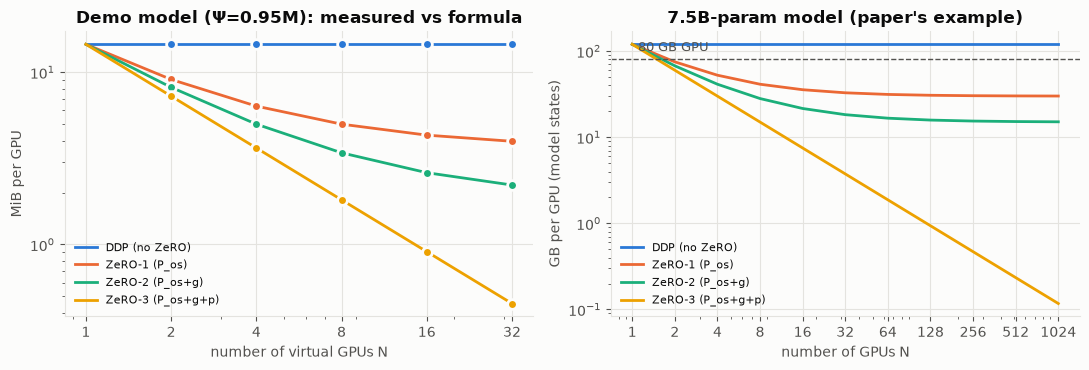

7.5B params, N=64 (paper Fig. 1: 120, 31.4, 16.6, 1.9 GB): [120.0, 31.4, 16.6, 1.9]


In [17]:
Ns = [2, 4, 8, 16, 32]
meas = {s: [] for s in range(4)}
for n in Ns:
    for s in range(4):
        r = run(s, world=n, steps=1)
        meas[s].append(sum(r.model_state[0][c] for c in MODEL_STATE_CATS) / MB)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
nn = np.array([1, 2, 4, 8, 16, 32])
for s in range(4):
    ax.plot(nn, [sum(zero_model_state_bytes(PSI, n, s))/MB for n in nn], color=C[s], lw=2, label=STAGE_NAMES[s])
    ax.plot(Ns, meas[s], "o", color=C[s], ms=7, mec=SURF, mew=2)
ax.set(xscale="log", yscale="log", xlabel="number of virtual GPUs N", ylabel="MiB per GPU",
       title=f"Demo model (Ψ={PSI/1e6:.2f}M): measured vs formula")
ax.set_xticks(nn, [str(n) for n in nn]); ax.legend(fontsize=8)

ax = axes[1]
big = 7.5e9; nn2 = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024])
for s in range(4):
    ax.plot(nn2, [sum(zero_model_state_bytes(big, n, s))/1e9 for n in nn2], color=C[s], lw=2, label=STAGE_NAMES[s])
ax.axhline(80, color=INK2, lw=1, ls="--"); ax.text(1.1, 100, "80 GB GPU", color=INK2, fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="number of GPUs N", ylabel="GB per GPU (model states)",
       title="7.5B-param model (paper's example)")
ax.set_xticks(nn2, [str(n) for n in nn2]); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("7.5B params, N=64 (paper Fig. 1: 120, 31.4, 16.6, 1.9 GB):",
      [round(sum(zero_model_state_bytes(big, 64, s))/1e9, 1) for s in range(4)])

## 10. The memory ladder: a 30B model on 80 GB cards

Now apply the same formulas to a real-sized model: **30B parameters**, cards with
**74.5 GiB** (80 GB) of memory, 8 to 64 GPUs. This counts training state only.
Activations come on top.

* DDP and ZeRO-1 **never fit**, at any GPU count. Both replicate the fp16 weights and grads,
  which is 4 B/param = 111.8 GiB on every card, however many cards there are.
* ZeRO-2 levels off at 2 B/param (55.9 GiB), so it fits once 14Ψ/N is small enough: from 32 GPUs.
* ZeRO-3 has no floor. It fits from 8 GPUs.
* The 4 B/param floor fills a 74.5 GiB card at exactly **20B parameters**. Above 20B,
  ZeRO-1 is ruled out no matter how many GPUs you add.

The right-hand chart shows where each arrangement hits its wall. DDP (16 B/param) fits one card only up to about 4.7B parameters. ZeRO-1 (floor 4 B/param) stops at 20B, and ZeRO-2 (floor 2 B/param) at 40B. Past those sizes, adding GPUs does not help. Only ZeRO-3 keeps scaling.

| arrangement | 8 GPUs | 16 GPUs | 32 GPUs | 64 GPUs | comm / step |
|---|---|---|---|---|---|
| DDP (no ZeRO) | 447.0 GiB ✗ | 447.0 GiB ✗ | 447.0 GiB ✗ | 447.0 GiB ✗ | 2P |
| ZeRO-1 (P_os) | 153.7 GiB ✗ | 132.7 GiB ✗ | 122.2 GiB ✗ | 117.0 GiB ✗ | 2P |
| ZeRO-2 (P_os+g) | 104.8 GiB ✗ | 80.3 GiB ✗ | 68.1 GiB ✓ | 62.0 GiB ✓ | 2P |
| ZeRO-3 (P_os+g+p) | 55.9 GiB ✓ | 27.9 GiB ✓ | 14.0 GiB ✓ | 7.0 GiB ✓ | 3P |

replicated floor for DDP/ZeRO-1 (fp16 weights + grads): 4 B x 30B = 111.8 GiB
model size where that floor fills a 74.5 GiB card: 20.0B parameters


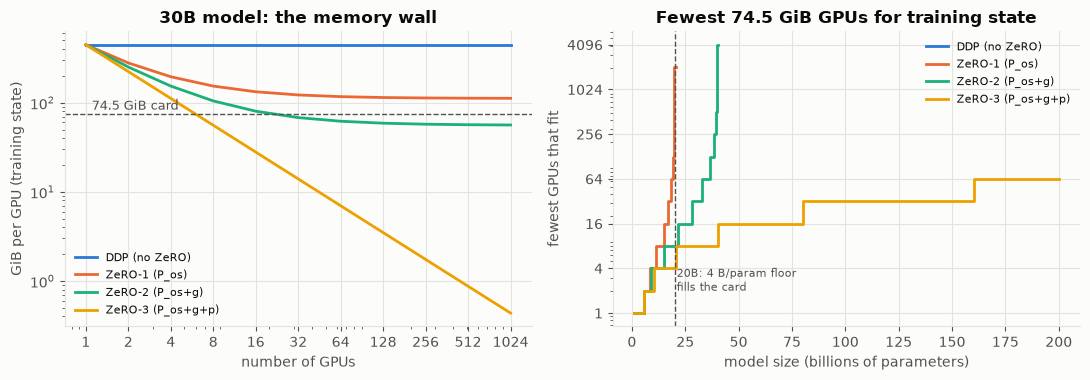

In [18]:
GiB, CARD, P30 = 2**30, 74.5, 30e9
Ns = [8, 16, 32, 64]
rows = []
for s in range(4):
    row = {"arrangement": STAGE_NAMES[s]}
    for n in Ns:
        g = sum(zero_model_state_bytes(P30, n, s)) / GiB
        row[f"{n} GPUs"] = f"{g:.1f} GiB" + (" ✓" if g <= CARD else " ✗")
    row["comm / step"] = "3P" if s == 3 else "2P"
    rows.append(row)
show_table(rows)
print(f"replicated floor for DDP/ZeRO-1 (fp16 weights + grads): 4 B x 30B = {4*P30/GiB:.1f} GiB")
print(f"model size where that floor fills a {CARD} GiB card: {CARD*GiB/4/1e9:.1f}B parameters")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
ax = axes[0]
nn = 2 ** np.arange(0, 11)
for s in range(4):
    ax.plot(nn, [sum(zero_model_state_bytes(P30, n, s)) / GiB for n in nn], color=C[s], lw=2, label=STAGE_NAMES[s])
ax.axhline(CARD, color=INK2, lw=1, ls="--"); ax.text(1.1, CARD * 1.12, "74.5 GiB card", color=INK2, fontsize=9)
ax.set(xscale="log", yscale="log", xlabel="number of GPUs", ylabel="GiB per GPU (training state)",
       title="30B model: the memory wall")
ax.set_xticks(nn, [str(n) for n in nn]); ax.legend(fontsize=8)

ax = axes[1]
sizes = np.linspace(1, 200, 400) * 1e9
for s in range(4):
    need = []
    for P in sizes:
        fit = [n for n in 2 ** np.arange(0, 13) if sum(zero_model_state_bytes(P, n, s)) / GiB <= CARD]
        need.append(fit[0] if fit else np.nan)
    ax.plot(sizes / 1e9, need, color=C[s], lw=2, label=STAGE_NAMES[s], drawstyle="steps-post")
ax.axvline(20, color=INK2, lw=1, ls="--"); ax.text(21, 2, "20B: 4 B/param floor\nfills the card", color=INK2, fontsize=8)
ax.set(yscale="log", xlabel="model size (billions of parameters)", ylabel="fewest GPUs that fit",
       title="Fewest 74.5 GiB GPUs for training state")
ax.set_yticks([1, 4, 16, 64, 256, 1024, 4096], ["1", "4", "16", "64", "256", "1024", "4096"]); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 11. Summary

| | model state / GPU | comm / step | optimizer work / GPU | extra temporaries |
|---|---|---|---|---|
| DDP | 16Ψ | 2Ψ | Ψ | – |
| ZeRO-1 | 4Ψ + 12Ψ/N | 2Ψ | Ψ/N | – |
| ZeRO-2 | 2Ψ + 14Ψ/N | 2Ψ | Ψ/N | one layer's full grad |
| ZeRO-3 | 16Ψ/N | 3Ψ | Ψ/N | one layer's full params + grad |

(Communication is in elements, ×(N-1)/N for a ring. Model-state and communication numbers were *measured* in the simulator. They match the formulas exactly because N divides every layer's size here. Otherwise per-layer padding adds a few bytes.)

Not simulated here: overlap of communication with compute, bucketing/prefetch, CPU/NVMe
offload (ZeRO-Offload/Infinity), activation partitioning (ZeRO-R), and loss scaling for fp16.